In [1]:
'''
Models trained and evaluated on clean_data.csv with 
all NaN values dropped.
'''

# 0. Programming Environment Setup

# Numerical computing and data handling
import numpy as np
import pandas as pd
from pathlib import Path

# Plotting and notebook-style table display
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from IPython.display import display

# Model utilities and evaluation
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    max_error,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# Regression models
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.kernel_ridge import KernelRidge
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

In [2]:
# 1. Data Preparation

# Fix random seed
RANDOM_SEED = 1
np.random.seed(RANDOM_SEED)

# Import Data
DATA_DIR = Path.cwd().parent / "EDA"
INPUT_FILE = DATA_DIR / "cleaned_data.csv"

df = pd.read_csv(INPUT_FILE, keep_default_na=False, na_values=[""])

# Remove rows containing missing values
df = df.dropna()

# Define target and feature variables
TARGET = 'log_half_life'
FEATURES = [
    "A",
    "N/Z",
    "Q_beta_keV",
    "Q_alpha_keV",
    "S_n_keV",
    "S_p_keV"
]

# Split the data into training and testing sets
df_train, df_test = train_test_split(
    df,
    test_size=0.2,
    random_state=RANDOM_SEED
)

# Define a function to get regression metrics
def get_regression_metrics(model, X, y_true):
    """
    Get a dicionary with regression metrics:

    model: sklearn model with predict method
    X: feature matrix
    y_true: ground truth labels
    """
    y_predicted = model.predict(X)

    mae = mean_absolute_error(y_true, y_predicted)
    mse = mean_squared_error(y_true, y_predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_predicted)
    maximum_error = max_error(y_true, y_predicted)


    metrics_dict = {
        'mae': mae,
        'mse': mse,
        'rmse': rmse,
        'r2': r2,
        'max_error': maximum_error,
    }

    return metrics_dict

# Define function for parity plots
def hist_density(y_true, y_pred, xlabel='y true', ylabel='y pred',
                 title=None, bins=50, ax=None, lims=None):
    """Parity plot drawn as a 2D histogram.

    y_true: true values
    y_pred: predicted values
    ax: optional Matplotlib subplot
    lims: optional shared axis limits
    """
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)

    if lims is None:
        lims = [
            min(y_true.min(), y_pred.min()),
            max(y_true.max(), y_pred.max())
        ]

    mae = np.mean(np.abs(y_true - y_pred))

    # Create a figure only if no axis is provided
    if ax is None:
        fig, ax = plt.subplots(figsize=(5.5, 4.5))
    else:
        fig = ax.figure

    # Plot 2D histogram
    h = ax.hist2d(
        y_true, y_pred,
        bins=bins,
        range=[lims, lims],
        cmin=1,
        cmap='viridis',
        norm=LogNorm()
    )

    # Add colorbar
    fig.colorbar(h[3], ax=ax, label='Number of Isotopes')

    # Add perfect prediction line
    ax.plot(lims, lims, 'k--', lw=1, label='y = x')

    # Set axis labels and title
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(
        f"{title} (MAE = {mae:.2f})"
        if title else f"MAE = {mae:.2f}"
    )

    ax.legend(loc='upper left')
    ax.set_xlim(lims)
    ax.set_ylim(lims)

    # Display only if standalone
    if ax is not None and fig.axes[0] == ax and len(fig.axes) == 2:
        pass

    return ax


In [3]:
# 2. Build Baseline Models

# Define Dummy Regressors
dummy_regressors = {
    'Dummy (mean)': DummyRegressor(strategy='mean'),
    'Dummy (median)': DummyRegressor(strategy='median')
}

# Initialize result dictionaries
dummy_models_train_results = {}
dummy_models_test_results = {}

# Train and evaluate each model
for name, regressor in dummy_regressors.items():

    # Fit model on training data
    regressor.fit(df_train[FEATURES], df_train[TARGET])

    # Evaluate on training set
    dummy_models_train_results[name] = get_regression_metrics(
        regressor, df_train[FEATURES], df_train[TARGET]
    )

    # Evaluate on test set
    dummy_models_test_results[name] = get_regression_metrics(
        regressor, df_test[FEATURES], df_test[TARGET]
    )

# Create DataFrames
df_dummy_train_results = pd.DataFrame.from_dict(
    dummy_models_train_results, orient='index'
)

df_dummy_test_results = pd.DataFrame.from_dict(
    dummy_models_test_results, orient='index'
)

# Combine training and testing results side-by-side
df_dummy_comparison = pd.concat(
    {'Train': df_dummy_train_results, 'Test': df_dummy_test_results},
    axis=1
)

df_dummy_comparison.index.name = 'Model'

# Display results
print("Comparison of Dummy Regressor Performance\n")
display(df_dummy_comparison.round(4))

Comparison of Dummy Regressor Performance



Train                                       Test          \
                   mae      mse    rmse      r2 max_error     mae     mse   
Model                                                                       
Dummy (mean)    2.4212  10.3360  3.2150  0.0000   10.5930  2.5383  11.343   
Dummy (median)  2.4208  10.3382  3.2153 -0.0002   10.6404  2.5376  11.346   

                                          
                  rmse      r2 max_error  
Model                                     
Dummy (mean)    3.3679 -0.0000    9.3872  
Dummy (median)  3.3684 -0.0003    9.4346

In [4]:
# 3. Build Linear Regression Models

# Define baseline Linear Regression models
linear_regressors = {

    'OLS': Pipeline([
        ('scaling', StandardScaler()),
        ('ols', LinearRegression())
    ]),

    'Ridge': Pipeline([
        ('scaling', StandardScaler()),
        ('ridge', Ridge())
    ]),

    'Lasso': Pipeline([
        ('scaling', StandardScaler()),
        ('lasso', Lasso(max_iter=10000))
    ]),

    'Elastic Net': Pipeline([
        ('scaling', StandardScaler()),
        ('elasticnet', ElasticNet(max_iter=10000))
    ]),

    'Polynomial': Pipeline([
        ('scaling', StandardScaler()),
        ('poly', PolynomialFeatures(degree=2, include_bias=False)),
        ('poly_scaling', StandardScaler()),
        ('ols', LinearRegression())
    ])
}

# Define hyperparameter grids for optimization
linear_param_grids = {

    'Ridge': {
        'ridge__alpha': [0.001, 0.01, 0.1, 1, 10, 100]
    },

    'Lasso': {
        'lasso__alpha': [0.001, 0.01, 0.1, 1, 10, 100]
    },

    'Elastic Net': {
        'elasticnet__alpha': [0.001, 0.01, 0.1, 1, 10, 100],
        'elasticnet__l1_ratio': [0.2, 0.5, 0.8]
    },

    'Polynomial': {
        'poly__degree': [1, 2, 3]
    }
}

# Initialize baseline results dictionary
linear_baseline_regressors = {}

# Train baseline models
for name, regressor in linear_regressors.items():

    # Clone baseline model
    baseline = clone(regressor)

    # Fit using training data only
    baseline.fit(df_train[FEATURES], df_train[TARGET])

    # Store fitted baseline
    linear_baseline_regressors[name] = baseline


# Initialize optimization results dictionary
linear_optimization_results = {}

# Initialize optimized model dictionary
linear_optimized_regressors = {}

# Optimize regression models using 5-fold cross-validation
for name, param_grid in linear_param_grids.items():

    grid = GridSearchCV(
        estimator=clone(linear_regressors[name]),
        param_grid=param_grid,
        cv=5,
        scoring='neg_mean_absolute_error',
        n_jobs=2,
        verbose=1
    )

    # Fit using training data only
    grid.fit(df_train[FEATURES], df_train[TARGET])

    # Store optimization results
    linear_optimization_results[name] = grid

    # Store optimized model
    linear_optimized_regressors[name] = grid.best_estimator_

    # Display best hyperparameters
    print(f"\n{name} Best Parameters:")
    print(grid.best_params_)
    print("Cross-Validation MAE:", -grid.best_score_)

# Initialize combined regression dictionary
linear_comparison_regressors = {}

for name in linear_regressors:

    # Add baseline model
    linear_comparison_regressors[
        f'{name} - Baseline'
    ] = linear_baseline_regressors[name]

    # Add optimized model (except OLS)
    if name in linear_optimized_regressors:

        linear_comparison_regressors[
            f'{name} - Optimized'
        ] = linear_optimized_regressors[name]


# Initialize result dictionaries
linear_regressor_results_train = {}
linear_regressor_results_test = {}

# Evaluate baseline and optimized models
for name, regressor in linear_comparison_regressors.items():

    # Evaluate on training set
    linear_regressor_results_train[name] = get_regression_metrics(
        regressor, df_train[FEATURES], df_train[TARGET]
    )

    # Evaluate on test set
    linear_regressor_results_test[name] = get_regression_metrics(
        regressor, df_test[FEATURES], df_test[TARGET]
    )

# Create comparison DataFrames
df_linear_train_results = pd.DataFrame.from_dict(
    linear_regressor_results_train, orient='index'
)

df_linear_test_results = pd.DataFrame.from_dict(
    linear_regressor_results_test, orient='index'
)

# Combine training and testing results side-by-side
df_linear_comparison = pd.concat(
    {'Train': df_linear_train_results, 'Test': df_linear_test_results},
    axis=1
)

df_linear_comparison.index.name = 'Model'

# Display results
print("\nComparison of Linear Regression Model Performance\n")

with pd.option_context(
    'display.max_rows', None,
    'display.max_columns', None,
    'display.width', 2000
):
    display(df_linear_comparison.round(4))



Fitting 5 folds for each of 6 candidates, totalling 30 fits

Ridge Best Parameters:
{'ridge__alpha': 10}
Cross-Validation MAE: 2.263269860938893
Fitting 5 folds for each of 6 candidates, totalling 30 fits

Lasso Best Parameters:
{'lasso__alpha': 0.01}
Cross-Validation MAE: 2.2604081536163743
Fitting 5 folds for each of 18 candidates, totalling 90 fits

Elastic Net Best Parameters:
{'elasticnet__alpha': 0.01, 'elasticnet__l1_ratio': 0.8}
Cross-Validation MAE: 2.261023585587897
Fitting 5 folds for each of 3 candidates, totalling 15 fits

Polynomial Best Parameters:
{'poly__degree': 2}
Cross-Validation MAE: 1.7715893034261705

Comparison of Linear Regression Model Performance



Train                                       Test                                   
                            mae      mse    rmse      r2 max_error     mae      mse    rmse      r2 max_error
Model                                                                                                        
OLS - Baseline           2.2449   9.3071  3.0508  0.0995   10.3806  2.3705  10.2929  3.2082  0.0926    9.4105
Ridge - Baseline         2.2445   9.3074  3.0508  0.0995   10.3835  2.3711  10.2979  3.2090  0.0921    9.4135
Ridge - Optimized        2.2438   9.3247  3.0536  0.0978   10.4055  2.3772  10.3454  3.2164  0.0879    9.4373
Lasso - Baseline         2.4212  10.3360  3.2150  0.0000   10.5930  2.5383  11.3430  3.3679 -0.0000    9.3872
Lasso - Optimized        2.2433   9.3193  3.0528  0.0984   10.4006  2.3760  10.3388  3.2154  0.0885    9.4569
Elastic Net - Baseline   2.4113  10.2800  3.2062  0.0054   10.6033  2.5301  11.2752  3.3579  0.0060    9.3969
Elastic Net - Optimized  2.2435   9.3224  3.0533  0.0981   10.4029  2.3766  10.3426  3.2160  0.0882    9.4613
Polynomial - Baseline    1.6458   5.5977  2.3659  0.4584    9.6375  1.8599  12.2771  3.5039 -0.0824   46.5440
Polynomial - Optimized   1.6458   5.5977  2.3659  0.4584    9.6375  1.8599  12.2771  3.5039 -0.0824   46.5440

In [5]:
# 4. Build Kernel Regression Models

# Define baseline Kernel Regression models
kernel_regressors = {

    'Kernel Ridge (RBF)': Pipeline([
        ('scaling', StandardScaler()),
        ('krr', KernelRidge(
            alpha=1.0,
            kernel='rbf'
        ))
    ]),

    'Support Vector Regression (RBF)': Pipeline([
        ('scaling', StandardScaler()),
        ('svr', SVR(
            kernel='rbf',
            C=1.0,
            epsilon=0.1,
            gamma='scale'
        ))
    ])
}

# Define hyperparameter grids
kernel_param_grids = {

    'Kernel Ridge (RBF)': {
        'krr__alpha': [0.01, 0.1, 1, 10],
        'krr__gamma': [0.001, 0.01, 0.1, 1]
    },

    'Support Vector Regression (RBF)': {
        'svr__C': [0.1, 1, 10, 100],
        'svr__epsilon': [0.01, 0.1, 1],
        'svr__gamma': ['scale', 0.01, 0.1]
    }
}

# Initialize baseline model dictionary
kernel_baseline_regressors = {}

# Train baseline models
for name, regressor in kernel_regressors.items():

    # Clone baseline model
    baseline = clone(regressor)

    # Fit using training data only
    baseline.fit(df_train[FEATURES], df_train[TARGET])

    # Store fitted baseline
    kernel_baseline_regressors[name] = baseline


# Initialize optimization results dictionary
kernel_optimization_results = {}

# Initialize optimized model dictionary
kernel_optimized_regressors = {}

# Optimize each kernel model using 5-fold cross-validation
for name, param_grid in kernel_param_grids.items():

    # Initialize GridSearchCV
    grid_kernel = GridSearchCV(
        estimator=clone(kernel_regressors[name]),
        param_grid=param_grid,
        cv=5,
        scoring='neg_mean_absolute_error',
        n_jobs=-1,
        verbose=1
    )

    # Fit using training data only
    grid_kernel.fit(df_train[FEATURES], df_train[TARGET])

    # Store optimization results
    kernel_optimization_results[name] = grid_kernel

    # Store optimized model
    kernel_optimized_regressors[name] = grid_kernel.best_estimator_
        
    # Display best hyperparameters
    print(f"\n{name} Best Parameters:")
    print(grid_kernel.best_params_)
    print("Cross-Validation MAE:", -grid_kernel.best_score_)


# Initialize combined Kernel Regression dictionary
kernel_comparison_regressors = {}

for name in kernel_regressors:

    # Add baseline model
    kernel_comparison_regressors[
        f'{name} - Baseline'
    ] = kernel_baseline_regressors[name]

    # Add optimized model
    if name in kernel_optimized_regressors:

        kernel_comparison_regressors[
            f'{name} - Optimized'
        ] = kernel_optimized_regressors[name]

# Initialize result dictionaries
kernel_regressor_results_train = {}
kernel_regressor_results_test = {}

# Evaluate baseline and optimized models
for name, regressor in kernel_comparison_regressors.items():

    # Evaluate on training set
    kernel_regressor_results_train[name] = get_regression_metrics(
        regressor, df_train[FEATURES], df_train[TARGET]
    )

    # Evaluate on test set
    kernel_regressor_results_test[name] = get_regression_metrics(
        regressor, df_test[FEATURES], df_test[TARGET]
    )

# Create comparison DataFrames
df_kernel_train_results = pd.DataFrame.from_dict(
    kernel_regressor_results_train, orient='index'
)

df_kernel_test_results = pd.DataFrame.from_dict(
    kernel_regressor_results_test, orient='index'
)

# Combine training and testing results side-by-side
df_kernel_comparison = pd.concat(
    {'Train': df_kernel_train_results, 'Test': df_kernel_test_results},
    axis=1
)

df_kernel_comparison.index.name = 'Model'

# Display results
print("\nComparison of Kernel Regression Model Performance\n")

with pd.option_context(
    'display.max_rows', None,
    'display.max_columns', None,
    'display.width', 2000
):
    display(df_kernel_comparison.round(4))


Fitting 5 folds for each of 16 candidates, totalling 80 fits

Kernel Ridge (RBF) Best Parameters:
{'krr__alpha': 0.1, 'krr__gamma': 1}
Cross-Validation MAE: 0.976639963850614
Fitting 5 folds for each of 36 candidates, totalling 180 fits

Support Vector Regression (RBF) Best Parameters:
{'svr__C': 100, 'svr__epsilon': 0.1, 'svr__gamma': 'scale'}
Cross-Validation MAE: 0.9996594488972749

Comparison of Kernel Regression Model Performance



Train                                      Test                                  
                                                mae     mse    rmse      r2 max_error     mae     mse    rmse      r2 max_error
Model                                                                                                                          
Kernel Ridge (RBF) - Baseline                1.1528  3.1160  1.7652  0.6985    7.8628  1.2397  3.4757  1.8643  0.6936    8.0991
Kernel Ridge (RBF) - Optimized               0.6862  1.1168  1.0568  0.8919    7.6357  0.9210  1.8842  1.3727  0.8339    5.7321
Support Vector Regression (RBF) - Baseline   1.1875  4.2651  2.0652  0.5874    8.8085  1.3323  4.8146  2.1942  0.5755    8.5880
Support Vector Regression (RBF) - Optimized  0.8249  2.2156  1.4885  0.7856    8.2257  0.9952  2.6108  1.6158  0.7698    8.2500

In [6]:
# 5. Build Tree-Based Regression Models

# Define baseline Tree-Based Regression models
tree_regressors = {

    'Decision Tree': DecisionTreeRegressor(
        random_state=RANDOM_SEED
    )
}

# Define hyperparameter grids
tree_param_grids = {

    'Decision Tree': {
        'max_depth': [None, 5, 10, 20],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 5]
    }
}

# Initialize baseline model dictionary
tree_baseline_regressors = {}

# Train baseline models
for name, regressor in tree_regressors.items():

    print(f"Training {name} Baseline...")

    # Clone baseline model
    baseline = clone(regressor)

    # Fit using training data only
    baseline.fit(df_train[FEATURES], df_train[TARGET])

    # Store fitted baseline
    tree_baseline_regressors[name] = baseline

# Initialize optimization results dictionary
tree_optimization_results = {}

# Initialize optimized model dictionary
tree_optimized_regressors = {}

# Optimize models using 5-fold cross-validation
for name, param_grid in tree_param_grids.items():

    grid_tree = GridSearchCV(
        estimator=clone(tree_regressors[name]),
        param_grid=param_grid,
        cv=5,
        scoring='neg_mean_absolute_error',
        n_jobs=2,
        verbose=1
    )

    # Fit using training data only
    grid_tree.fit(df_train[FEATURES], df_train[TARGET])

    # Store optimization results
    tree_optimization_results[name] = grid_tree

    # Store optimized model
    tree_optimized_regressors[name] = grid_tree.best_estimator_
    
    # Display best hyperparameters
    print(f"\n{name} Best Parameters:")
    print(grid_tree.best_params_)
    print("Cross-Validation MAE:", -grid_tree.best_score_)

# Initialize combined Tree-Based Regression dictionary
tree_comparison_regressors = {}

for name in tree_regressors:

    # Add baseline model
    tree_comparison_regressors[
        f'{name} - Baseline'
    ] = tree_baseline_regressors[name]

    # Add optimized model
    if name in tree_optimized_regressors:

        tree_comparison_regressors[
            f'{name} - Optimized'
        ] = tree_optimized_regressors[name]

# Initialize result dictionaries
tree_regressor_results_train = {}
tree_regressor_results_test = {}

# Evaluate baseline and optimized models
for name, regressor in tree_comparison_regressors.items():

    # Evaluate on training set
    tree_regressor_results_train[name] = get_regression_metrics(
        regressor, df_train[FEATURES], df_train[TARGET]
    )

    # Evaluate on test set
    tree_regressor_results_test[name] = get_regression_metrics(
        regressor, df_test[FEATURES], df_test[TARGET]
    )

# Create comparison DataFrames
df_tree_train_results = pd.DataFrame.from_dict(
    tree_regressor_results_train, orient='index'
)

df_tree_test_results = pd.DataFrame.from_dict(
    tree_regressor_results_test, orient='index'
)

# Combine training and testing results side-by-side
df_tree_comparison = pd.concat(
    {'Train': df_tree_train_results, 'Test': df_tree_test_results},
    axis=1
)

df_tree_comparison.index.name = 'Model'

# Display results
print("\nComparison of Tree-Based Regression Model Performance\n")

with pd.option_context(
    'display.max_rows', None,
    'display.max_columns', None,
    'display.width', 2000
):
    display(df_tree_comparison.round(4))


Training Decision Tree Baseline...
Fitting 5 folds for each of 36 candidates, totalling 180 fits

Decision Tree Best Parameters:
{'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 2}
Cross-Validation MAE: 1.1234456814827265

Comparison of Tree-Based Regression Model Performance



Train                                      Test                                  
                              mae     mse    rmse      r2 max_error     mae     mse    rmse      r2 max_error
Model                                                                                                        
Decision Tree - Baseline   0.0000  0.0000  0.0000  1.0000     0.000  1.2573  3.8849  1.9710  0.6575    7.8995
Decision Tree - Optimized  0.7195  1.2787  1.1308  0.8763     6.124  1.2046  2.9835  1.7273  0.7370    7.7708

In [7]:
# 6. Build Instance-Based Regression Models

# Define baseline Instance-Based Regression models
instance_regressors = {

    'k-NN': Pipeline([
        ('scaling', StandardScaler()),
        ('knn', KNeighborsRegressor())
    ])
}

# Define hyperparameter grids
instance_param_grids = {

    'k-NN': {
        'knn__n_neighbors': [3, 5, 10, 15, 20],
        'knn__weights': ['uniform', 'distance'],
        'knn__p': [1, 2]
    }
}

# Initialize baseline model dictionary
instance_baseline_regressors = {}

# Train baseline models
for name, regressor in instance_regressors.items():

    print(f"Training {name} Baseline...")

    # Clone baseline model
    baseline = clone(regressor)

    # Fit using training data only
    baseline.fit(df_train[FEATURES], df_train[TARGET])

    # Store fitted baseline
    instance_baseline_regressors[name] = baseline

# Initialize optimization results dictionary
instance_optimization_results = {}

# Initialize optimized model dictionary
instance_optimized_regressors = {}

# Optimize using 5-fold cross-validation
for name, param_grid in instance_param_grids.items():

    grid_instance = GridSearchCV(
        estimator=clone(instance_regressors[name]),
        param_grid=param_grid,
        cv=5,
        scoring='neg_mean_absolute_error',
        n_jobs=2,
        verbose=1,
        error_score='raise'
    )

    # Fit using training data only
    grid_instance.fit(df_train[FEATURES], df_train[TARGET])

    # Store optimization results
    instance_optimization_results[name] = grid_instance

    # Store optimized model
    instance_optimized_regressors[name] = grid_instance.best_estimator_
    
    # Display best hyperparameters
    print(f"\n{name} Best Parameters:")
    print(grid_instance.best_params_)
    print("Cross-Validation MAE:", -grid_instance.best_score_)

# Initialize combined Instance-Based Regression dictionary
instance_comparison_regressors = {}

for name in instance_regressors:

    # Add baseline model
    instance_comparison_regressors[
        f'{name} - Baseline'
    ] = instance_baseline_regressors[name]

    # Add optimized model
    if name in instance_optimized_regressors:

        instance_comparison_regressors[
            f'{name} - Optimized'
        ] = instance_optimized_regressors[name]


# Initialize result dictionaries
instance_regressor_results_train = {}
instance_regressor_results_test = {}

# Evaluate baseline and optimized models
for name, regressor in instance_comparison_regressors.items():

    # Evaluate on training set
    instance_regressor_results_train[name] = get_regression_metrics(
        regressor, df_train[FEATURES], df_train[TARGET]
    )

    # Evaluate on test set
    instance_regressor_results_test[name] = get_regression_metrics(
        regressor, df_test[FEATURES], df_test[TARGET]
    )

# Create comparison DataFrames
df_instance_train_results = pd.DataFrame.from_dict(
    instance_regressor_results_train, orient='index'
)

df_instance_test_results = pd.DataFrame.from_dict(
    instance_regressor_results_test, orient='index'
)

# Combine training and testing results side-by-side
df_instance_comparison = pd.concat(
    {
        'Train': df_instance_train_results,
        'Test': df_instance_test_results
    },
    axis=1
)

df_instance_comparison.index.name = 'Model'

# Display results
print("\nComparison of Instance-Based Regression Model Performance\n")

with pd.option_context(
    'display.max_rows', None,
    'display.max_columns', None,
    'display.width', 2000
):
    display(df_instance_comparison.round(4))

Training k-NN Baseline...
Fitting 5 folds for each of 20 candidates, totalling 100 fits

k-NN Best Parameters:
{'knn__n_neighbors': 10, 'knn__p': 1, 'knn__weights': 'distance'}
Cross-Validation MAE: 1.0506577340284804

Comparison of Instance-Based Regression Model Performance



Train                                      Test                                  
                     mae     mse    rmse      r2 max_error     mae     mse    rmse      r2 max_error
Model                                                                                               
k-NN - Baseline   0.8676  1.8035  1.3429  0.8255    7.9822  1.0669  2.5064  1.5831  0.7790    6.6040
k-NN - Optimized  0.0000  0.0000  0.0000  1.0000    0.0000  1.0285  2.3805  1.5429  0.7901    6.2283

In [8]:

# 7. Build Ensemble Regression Models

# Define base models for Stacking Regression
stacking_estimators = [

    ('ridge', Pipeline([
        ('scaling', StandardScaler()),
        ('ridge', Ridge())
    ])),

    ('svr', Pipeline([
        ('scaling', StandardScaler()),
        ('svr', SVR())
    ])),

    ('knn', Pipeline([
        ('scaling', StandardScaler()),
        ('knn', KNeighborsRegressor())
    ]))
]


# Define baseline Ensemble Regression models
ensemble_regressors = {

    'Random Forest': RandomForestRegressor(
        random_state=RANDOM_SEED,
        n_jobs=1
    ),

    'XGBoost': XGBRegressor(
        objective='reg:squarederror',
        random_state=RANDOM_SEED,
        tree_method='hist',
        n_jobs=1
    ),

    'Stacking': StackingRegressor(
        estimators=stacking_estimators,
        final_estimator=Ridge(),
        cv=5,
        n_jobs=1
    )
}


# Define hyperparameter grids
ensemble_param_grids = {

    'Random Forest': {
        'n_estimators': [100, 300],
        'max_depth': [None, 10, 20],
        'min_samples_leaf': [1, 2]
    },

    'XGBoost': {
        'n_estimators': [100, 300],
        'max_depth': [3, 5],
        'learning_rate': [0.01, 0.1],
        'subsample': [0.8, 1.0]
    },

    'Stacking': {
        'final_estimator__alpha': [0.1, 1, 10],
        'svr__svr__C': [0.1, 1, 10]
    }
}

# Initialize baseline model dictionary
ensemble_baseline_regressors = {}

# Train baseline models
for name, regressor in ensemble_regressors.items():

    # Clone baseline model
    baseline = clone(regressor)

    # Fit using training data only
    baseline.fit(
        df_train[FEATURES],
        df_train[TARGET]
    )

    # Store fitted baseline
    ensemble_baseline_regressors[name] = baseline

# Initialize optimization results dictionary
ensemble_optimization_results = {}

# Initialize optimized model dictionary
ensemble_optimized_regressors = {}

# Optimize models using 5-fold cross-validation
for name, param_grid in ensemble_param_grids.items():

    grid_ensemble = GridSearchCV(
        estimator=clone(ensemble_regressors[name]),
        param_grid=param_grid,
        cv=5,
        scoring='neg_mean_absolute_error',
        n_jobs=2,
        verbose=1,
        error_score='raise'
    )

    # Fit using training data only
    grid_ensemble.fit(
        df_train[FEATURES],
        df_train[TARGET]
    )

    # Store optimization results
    ensemble_optimization_results[name] = grid_ensemble

    # Store optimized model
    ensemble_optimized_regressors[name] = (
        grid_ensemble.best_estimator_
    )
    
    # Display best hyperparameters
    print(f"\n{name} Best Parameters:")
    print(grid_ensemble.best_params_)
    print("Cross-Validation MAE:", -grid_ensemble.best_score_)

# Initialize combined Ensemble Regression dictionary
ensemble_comparison_regressors = {}

for name in ensemble_regressors:

    # Add baseline model
    ensemble_comparison_regressors[
        f'{name} - Baseline'
    ] = ensemble_baseline_regressors[name]

    # Add optimized model
    if name in ensemble_optimized_regressors:

        ensemble_comparison_regressors[
            f'{name} - Optimized'
        ] = ensemble_optimized_regressors[name]

# Initialize result dictionaries
ensemble_regressor_results_train = {}
ensemble_regressor_results_test = {}

# Evaluate baseline and optimized models
for name, regressor in ensemble_comparison_regressors.items():

    # Evaluate on training set
    ensemble_regressor_results_train[name] = get_regression_metrics(
        regressor, df_train[FEATURES], df_train[TARGET]
    )

    # Evaluate on test set
    ensemble_regressor_results_test[name] = get_regression_metrics(
        regressor, df_test[FEATURES], df_test[TARGET]
    )

# Create comparison DataFrames
df_ensemble_train_results = pd.DataFrame.from_dict(
    ensemble_regressor_results_train, orient='index'
)

df_ensemble_test_results = pd.DataFrame.from_dict(
    ensemble_regressor_results_test, orient='index'
)

# Combine training and testing results side-by-side
df_ensemble_comparison = pd.concat(
    {
        'Train': df_ensemble_train_results,
        'Test': df_ensemble_test_results
    },
    axis=1
)

df_ensemble_comparison.index.name = 'Model'

# Display results
print("\nComparison of Ensemble Regression Model Performance\n")

with pd.option_context(
    'display.max_rows', None,
    'display.max_columns', None,
    'display.width', 2000
):
    display(df_ensemble_comparison.round(4))

Fitting 5 folds for each of 12 candidates, totalling 60 fits

Random Forest Best Parameters:
{'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 300}
Cross-Validation MAE: 0.9393544898878202
Fitting 5 folds for each of 16 candidates, totalling 80 fits

XGBoost Best Parameters:
{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 300, 'subsample': 0.8}
Cross-Validation MAE: 0.8898842287617933
Fitting 5 folds for each of 9 candidates, totalling 45 fits

Stacking Best Parameters:
{'final_estimator__alpha': 10, 'svr__svr__C': 10}
Cross-Validation MAE: 1.0961277046939366

Comparison of Ensemble Regression Model Performance



Train                                      Test                                  
                              mae     mse    rmse      r2 max_error     mae     mse    rmse      r2 max_error
Model                                                                                                        
Random Forest - Baseline   0.3420  0.2952  0.5433  0.9714    3.1715  0.9773  2.1065  1.4514  0.8143    6.4606
Random Forest - Optimized  0.3413  0.2769  0.5262  0.9732    3.0266  0.9767  2.1068  1.4515  0.8143    6.5577
XGBoost - Baseline         0.0976  0.0190  0.1377  0.9982    0.7561  0.9956  2.3081  1.5193  0.7965    7.2145
XGBoost - Optimized        0.1845  0.0626  0.2502  0.9939    1.0995  0.8958  1.8949  1.3766  0.8329    6.6405
Stacking - Baseline        0.9084  1.8228  1.3501  0.8236    7.9942  1.0974  2.4564  1.5673  0.7834    6.4641
Stacking - Optimized       0.9034  1.7861  1.3364  0.8272    8.0822  1.0695  2.2768  1.5089  0.7993    6.2741

Comparison of All Regression Model Performance




Dummy Regression Parity Plots



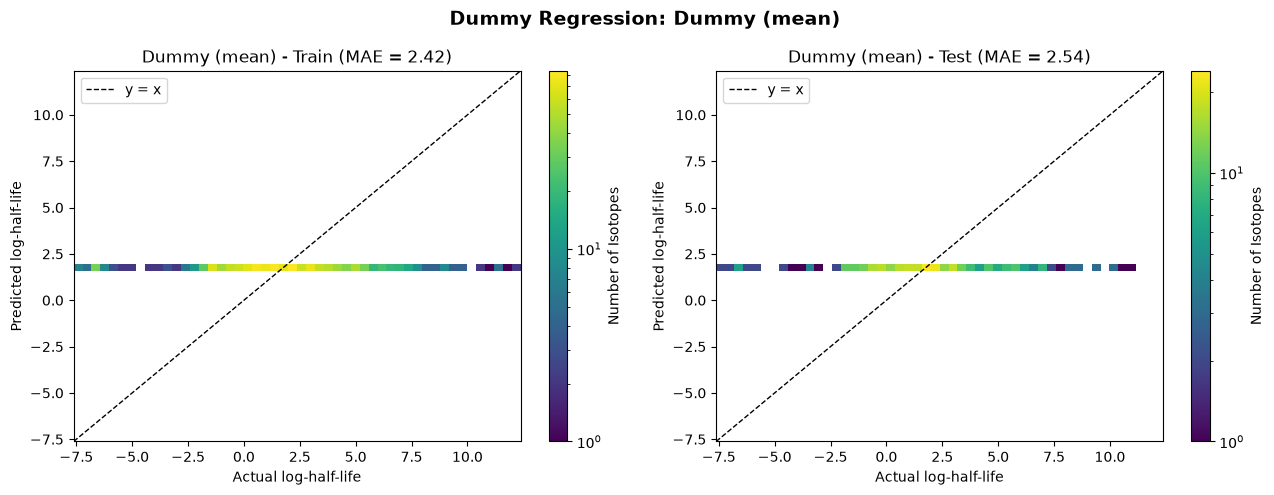

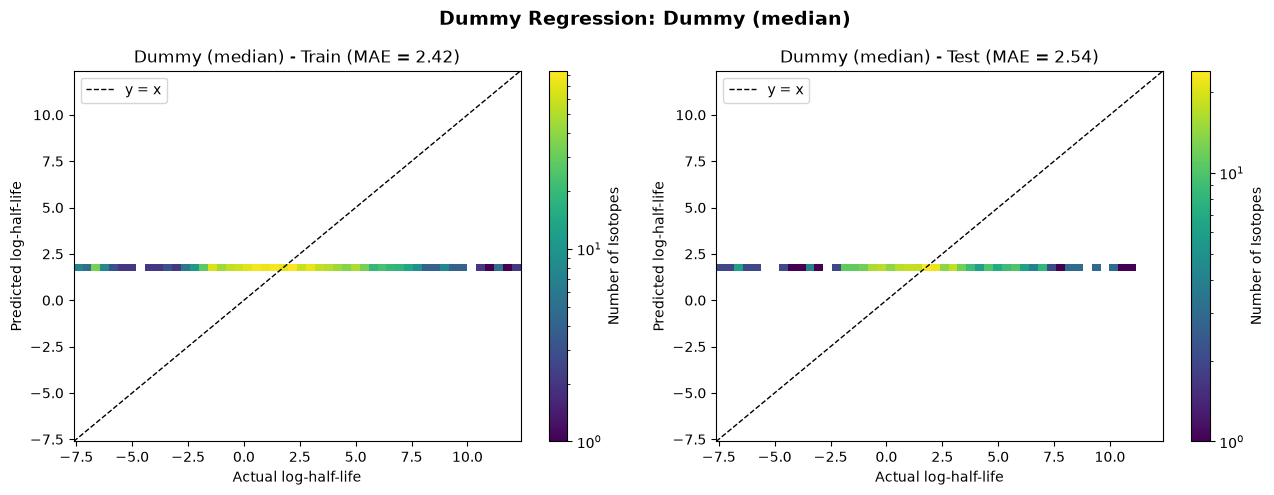


Linear Regression Parity Plots



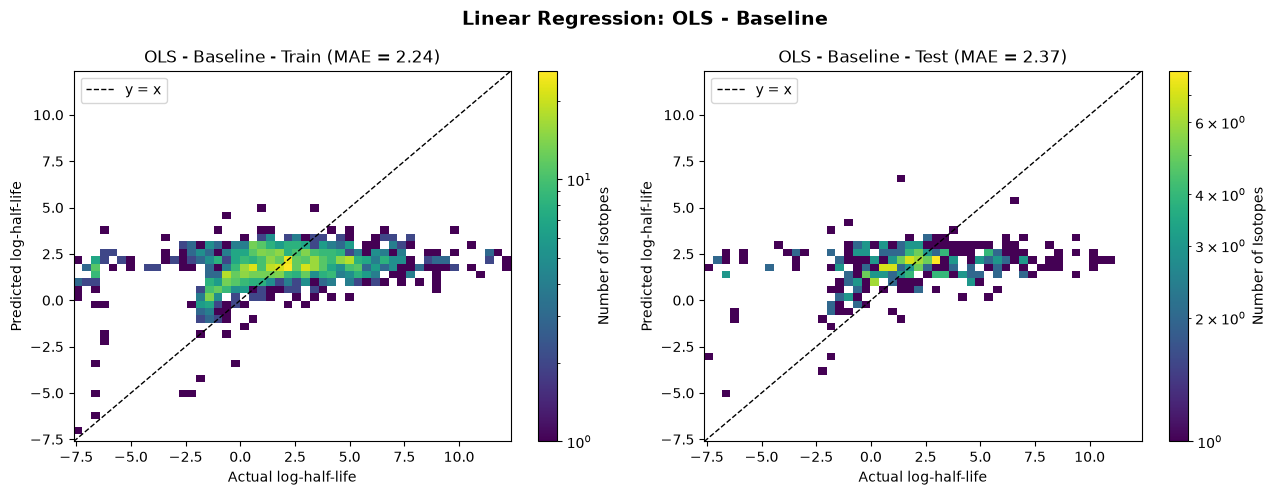

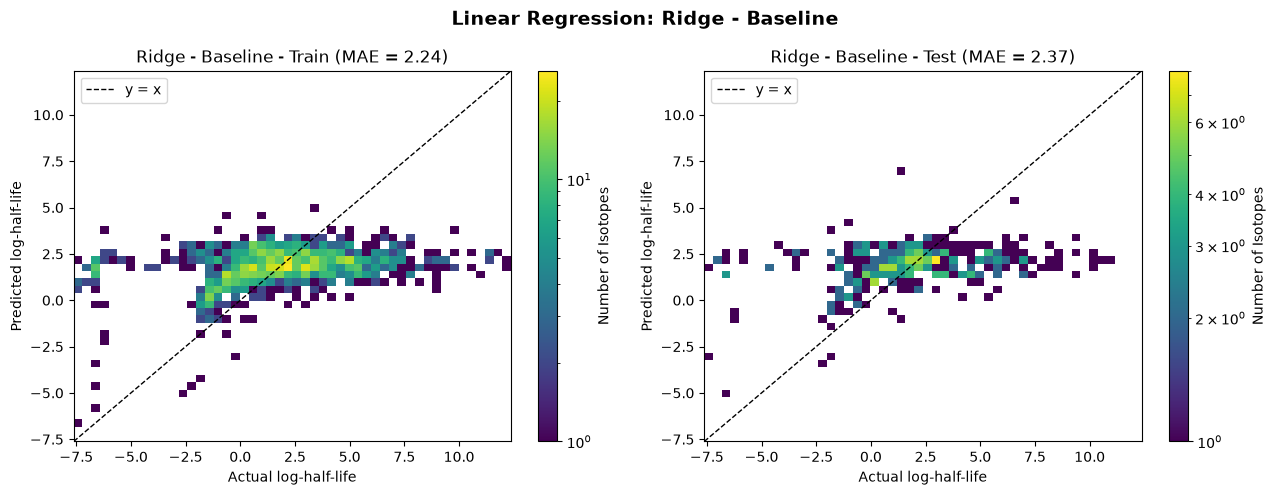

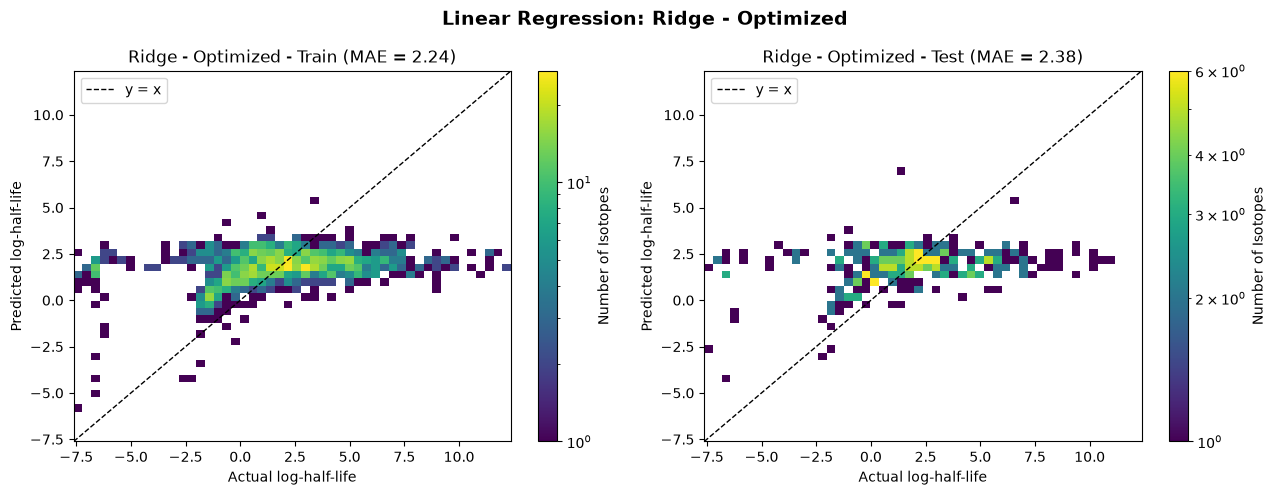

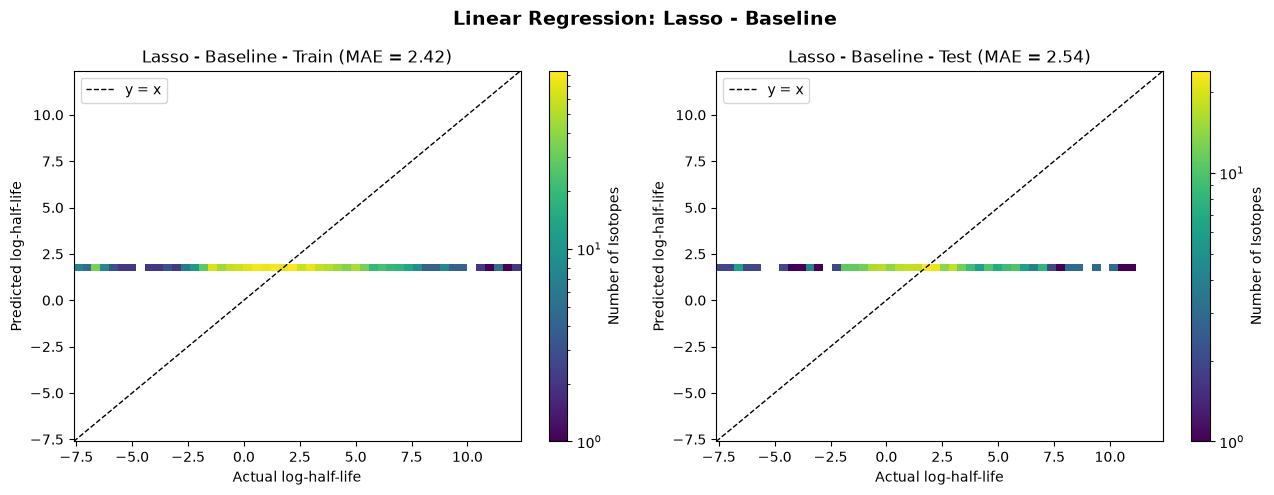

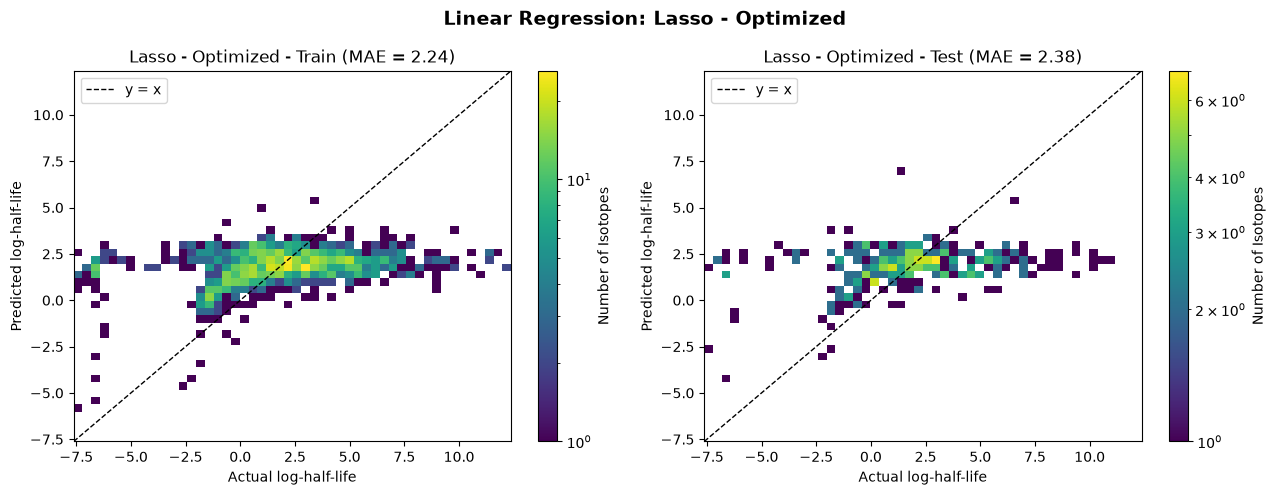

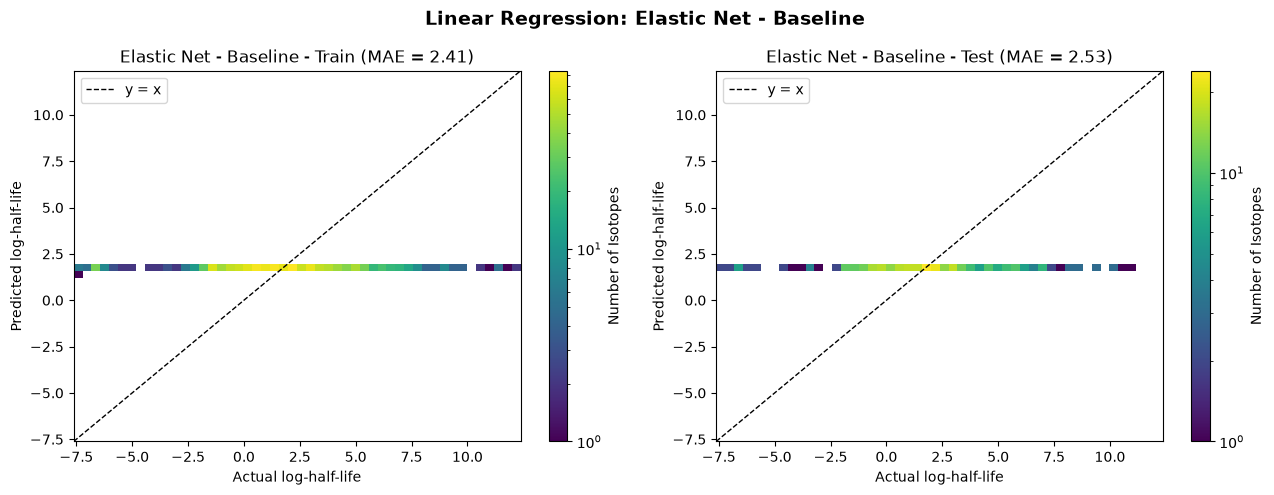

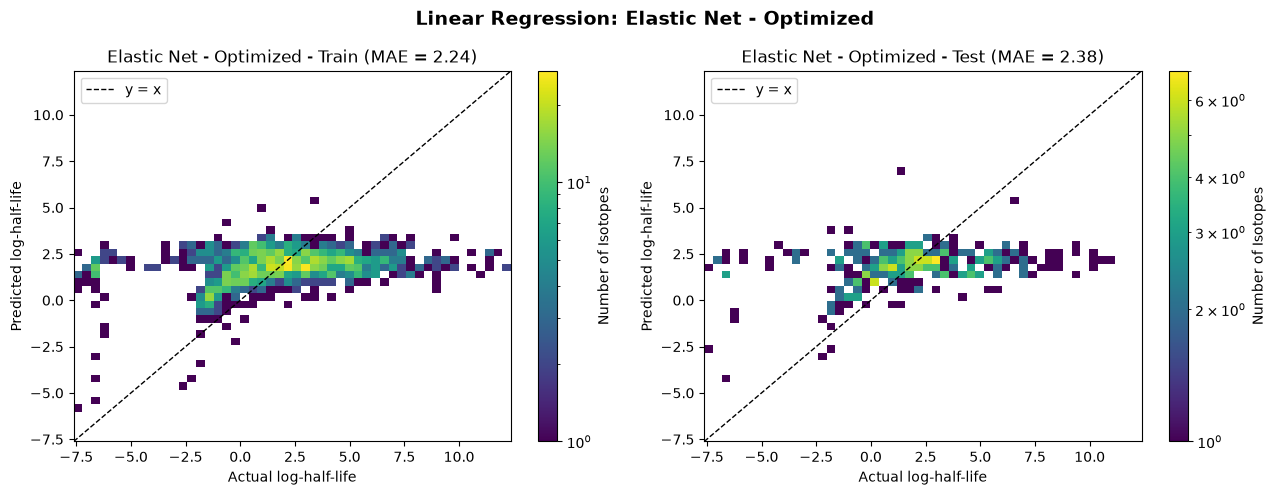

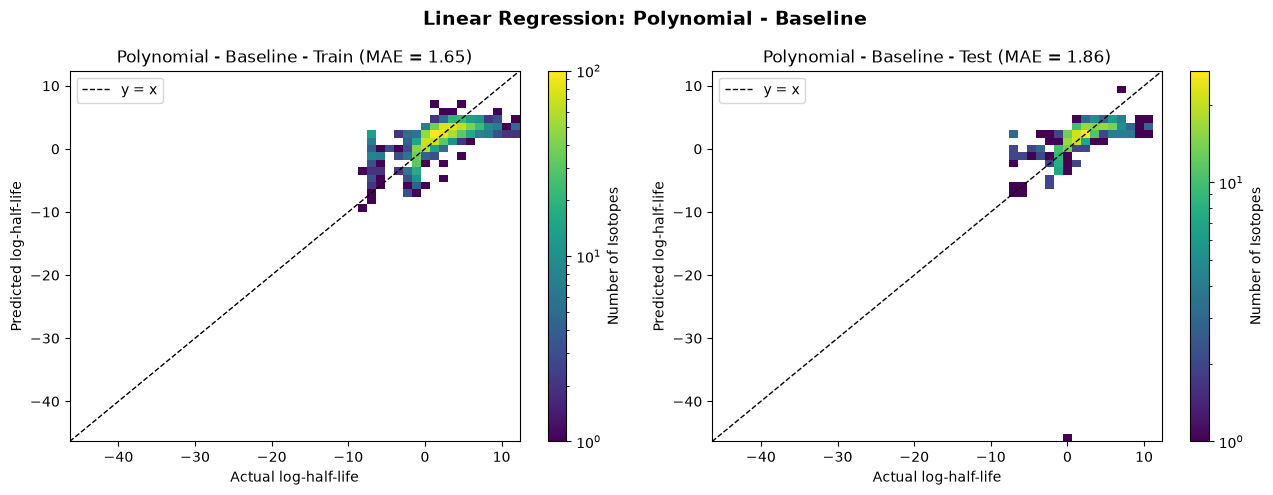

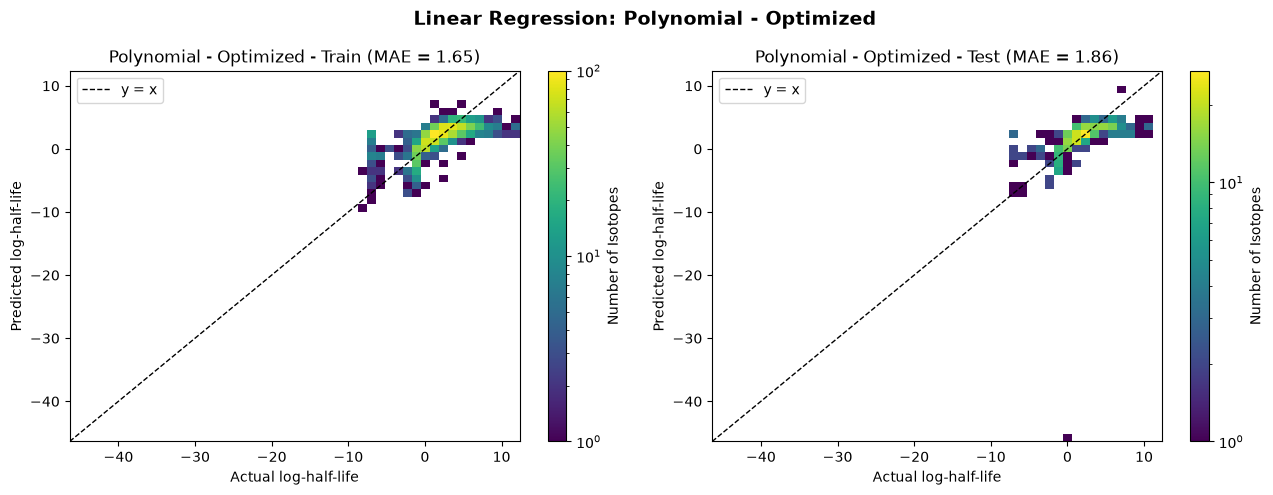


Kernel Regression Parity Plots



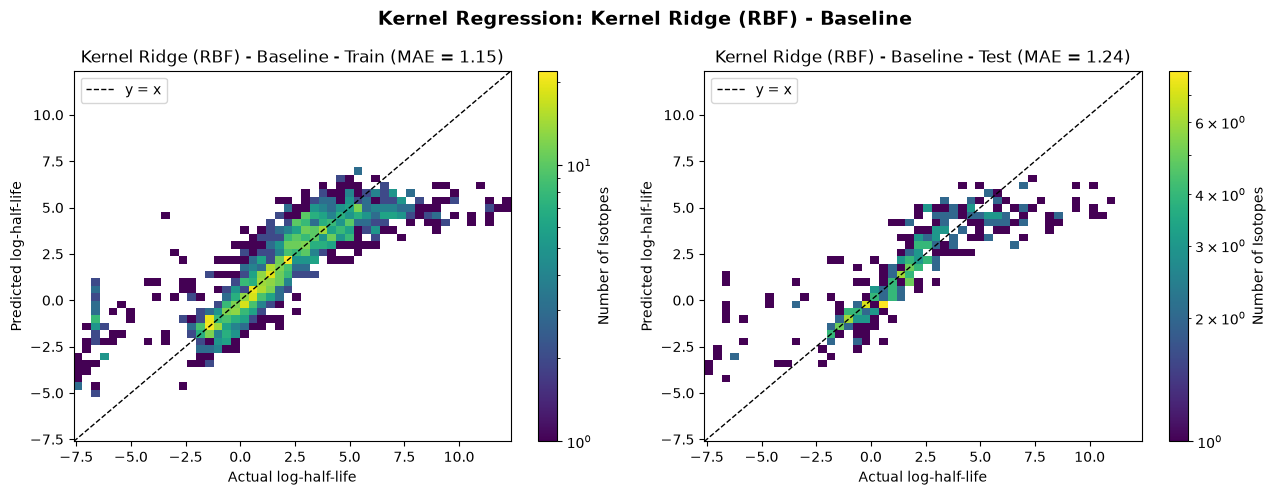

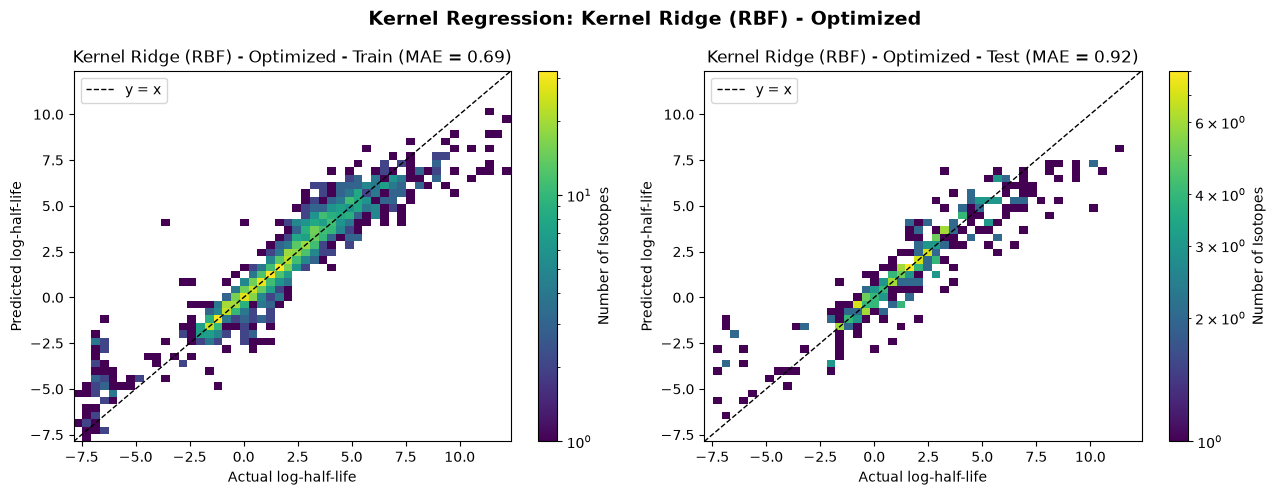

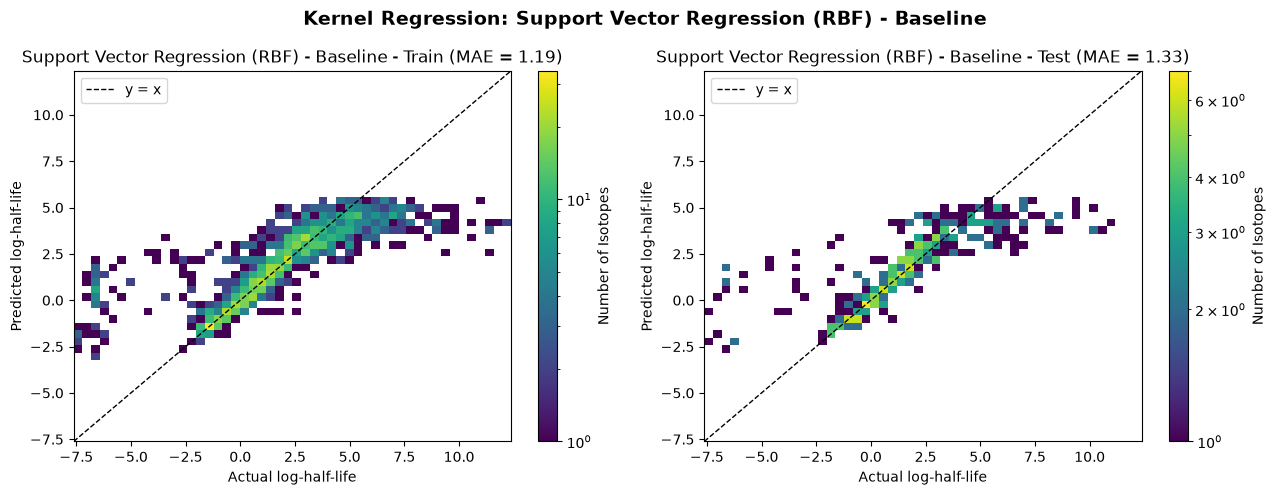

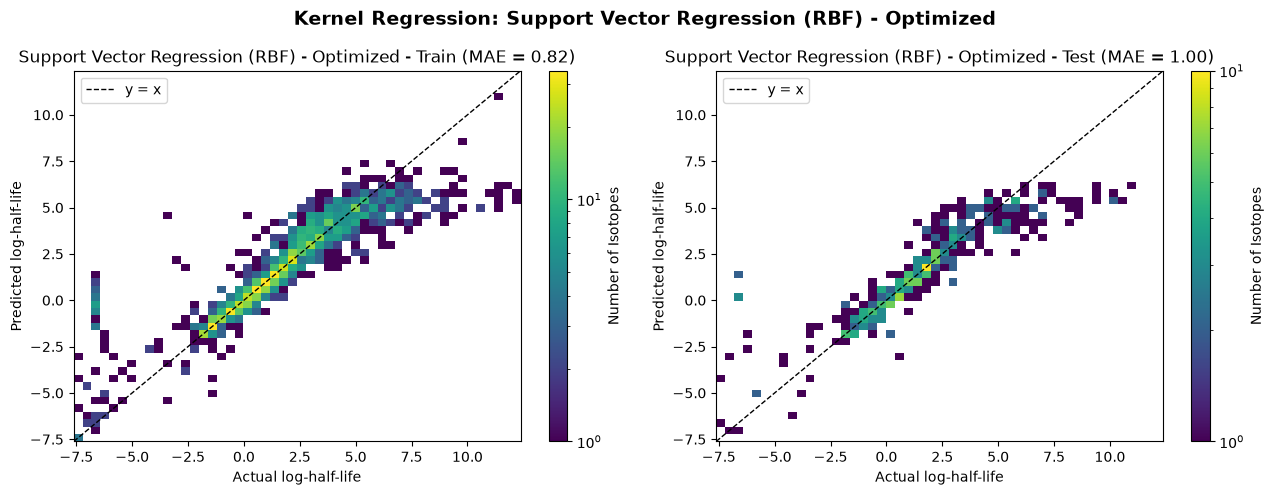


Tree-Based Regression Parity Plots



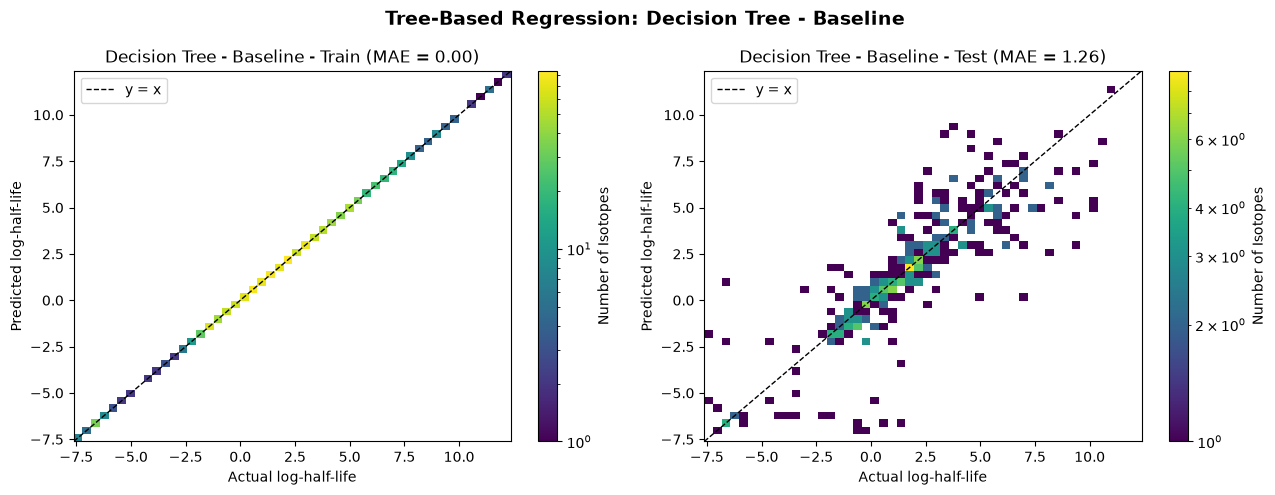

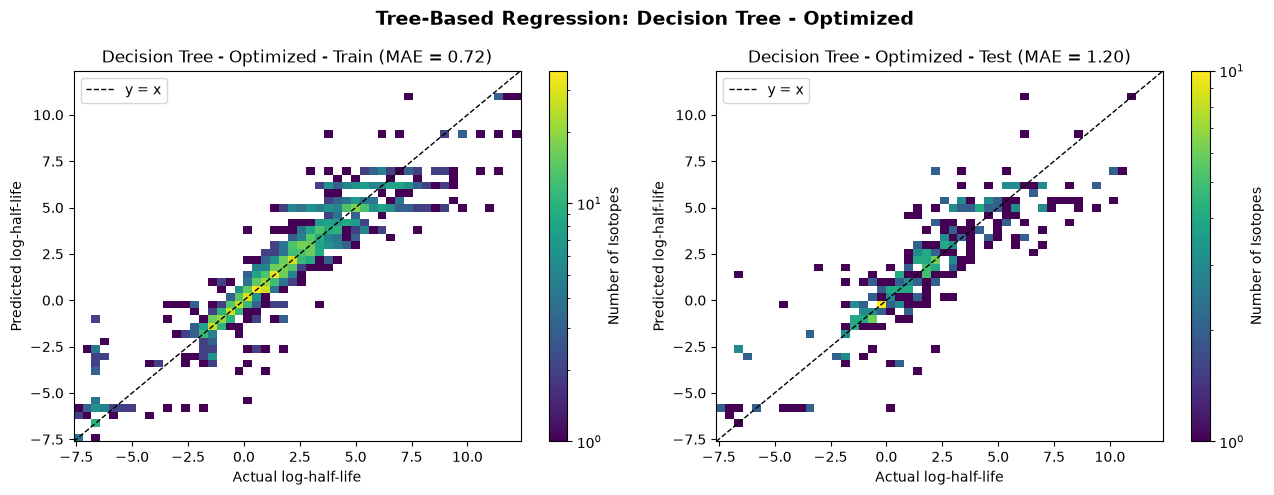


Instance-Based Regression Parity Plots



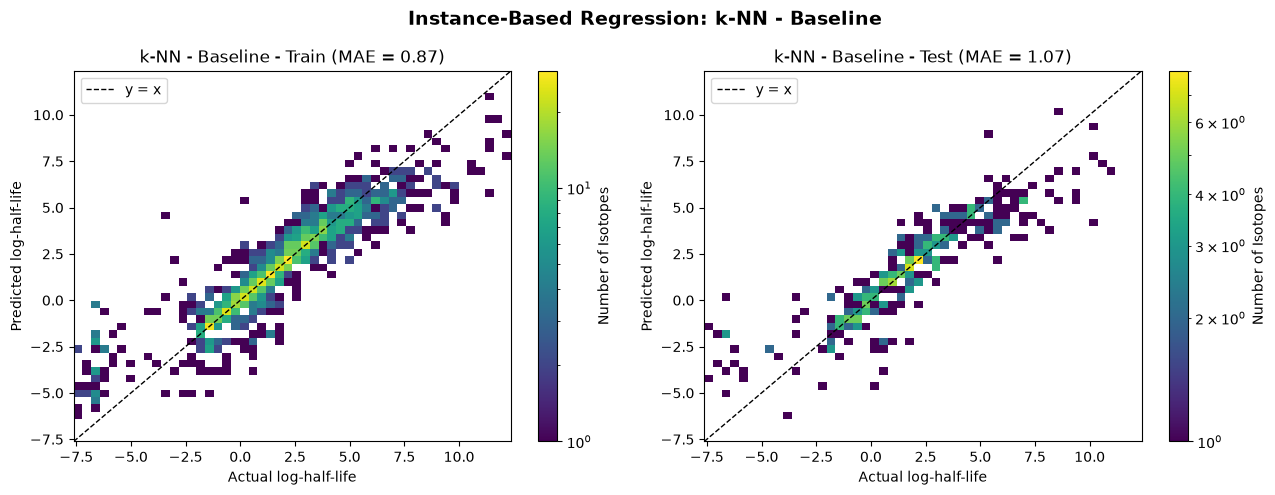

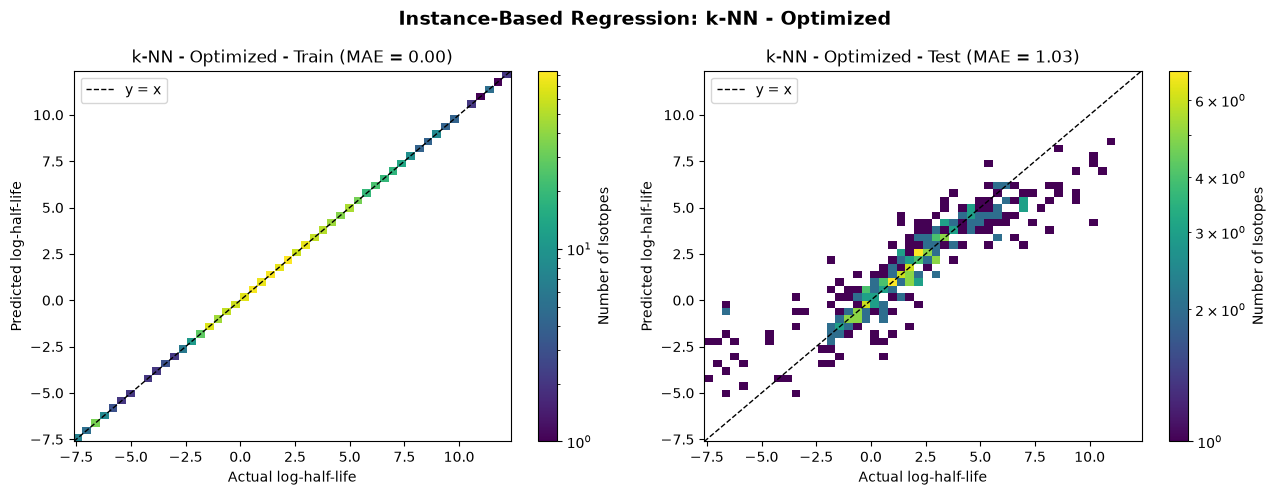


Ensemble Regression Parity Plots



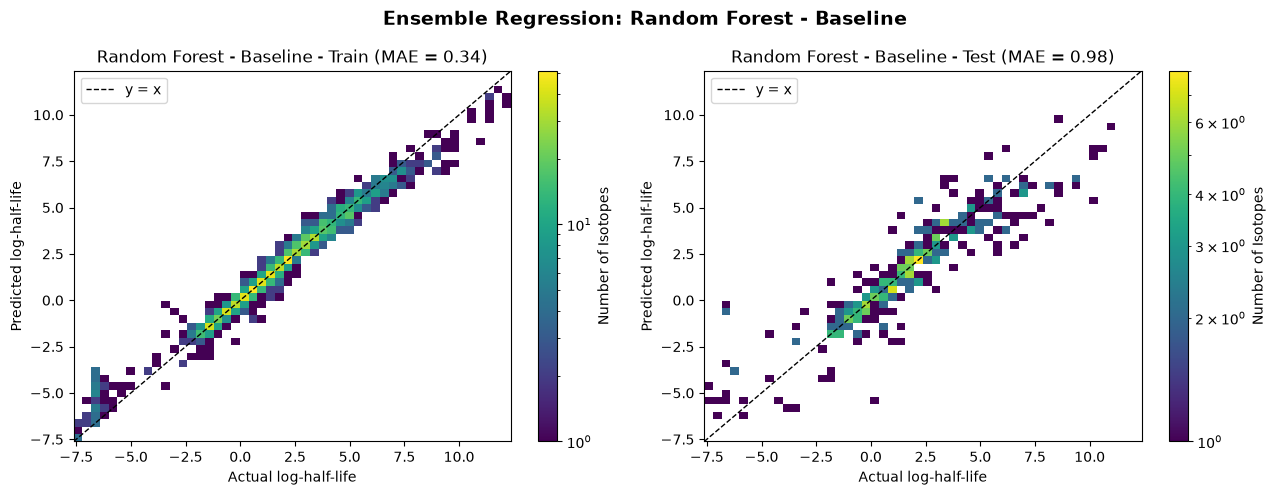

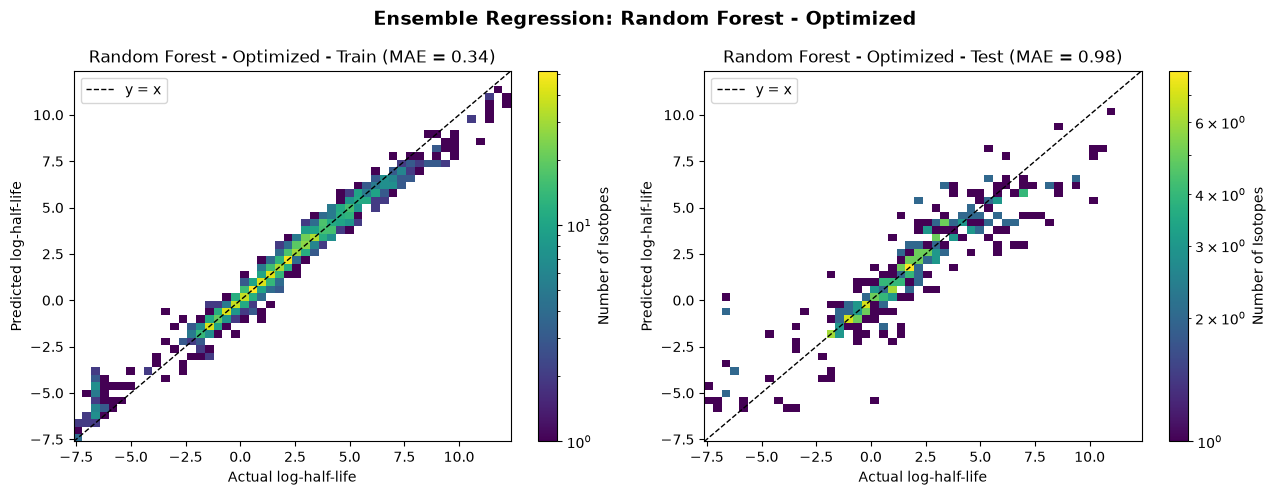

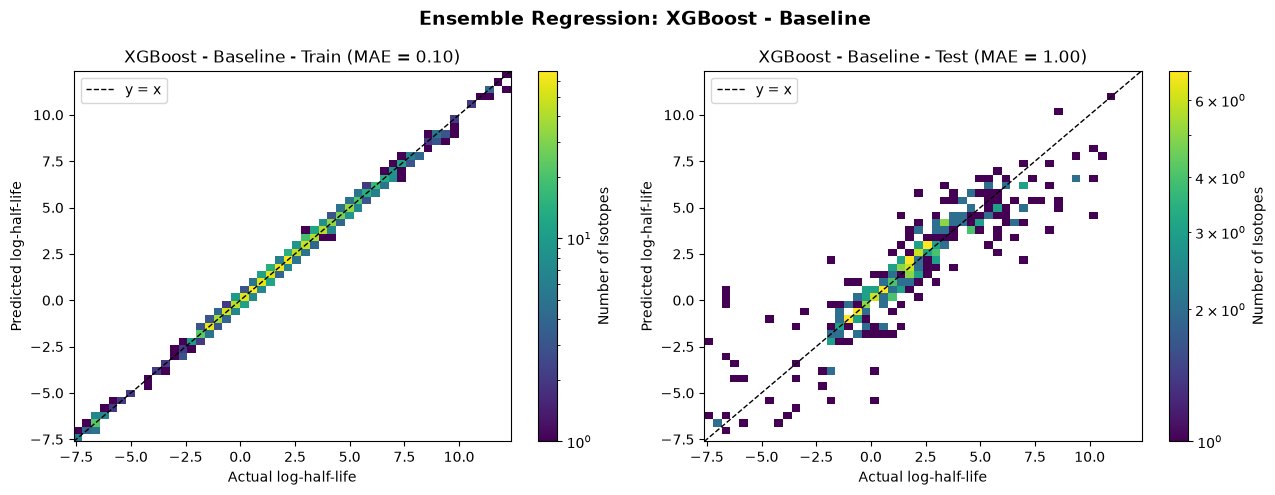

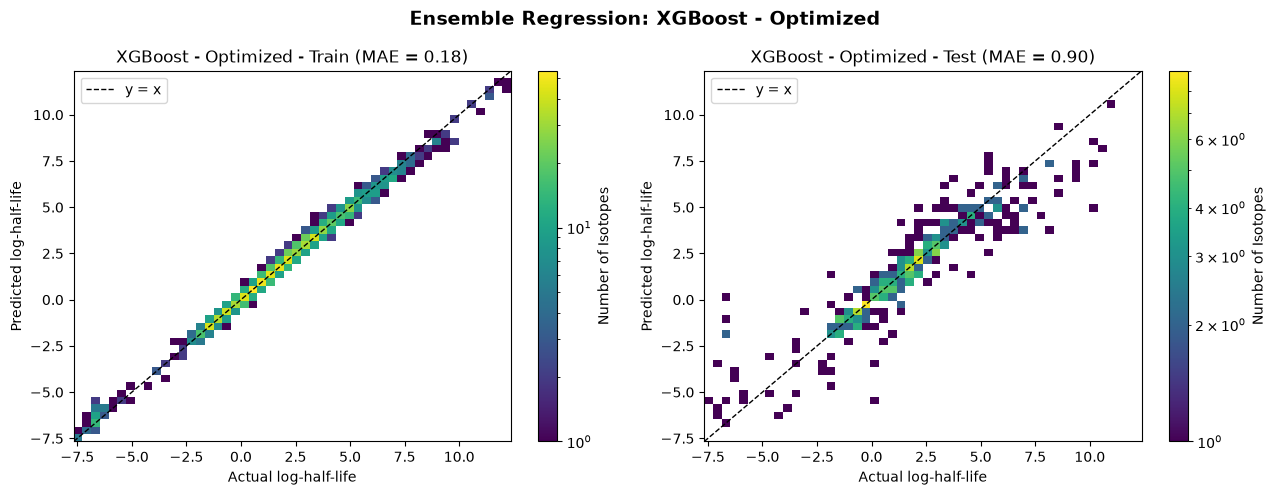

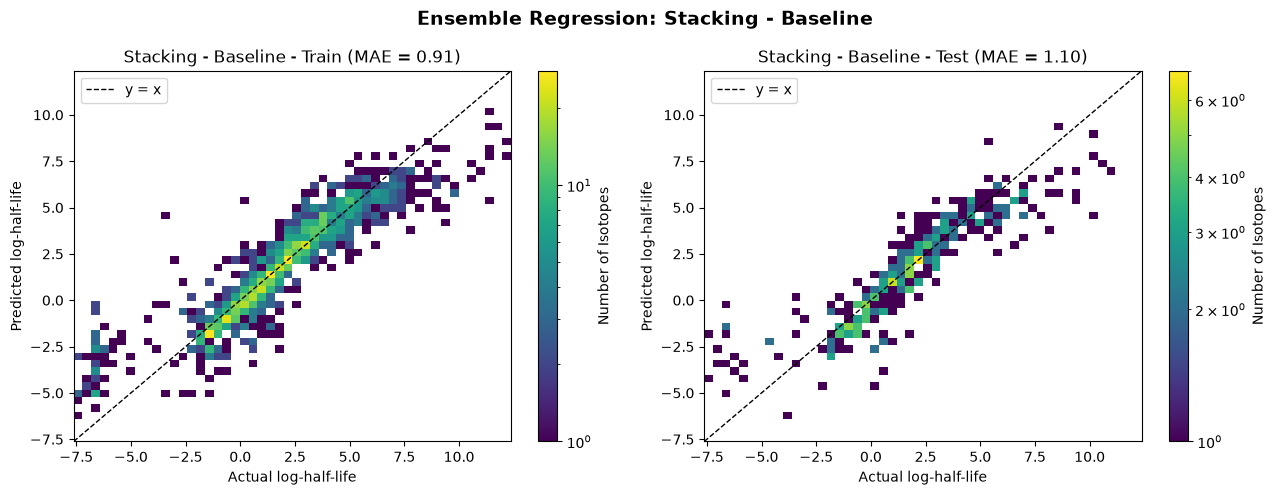

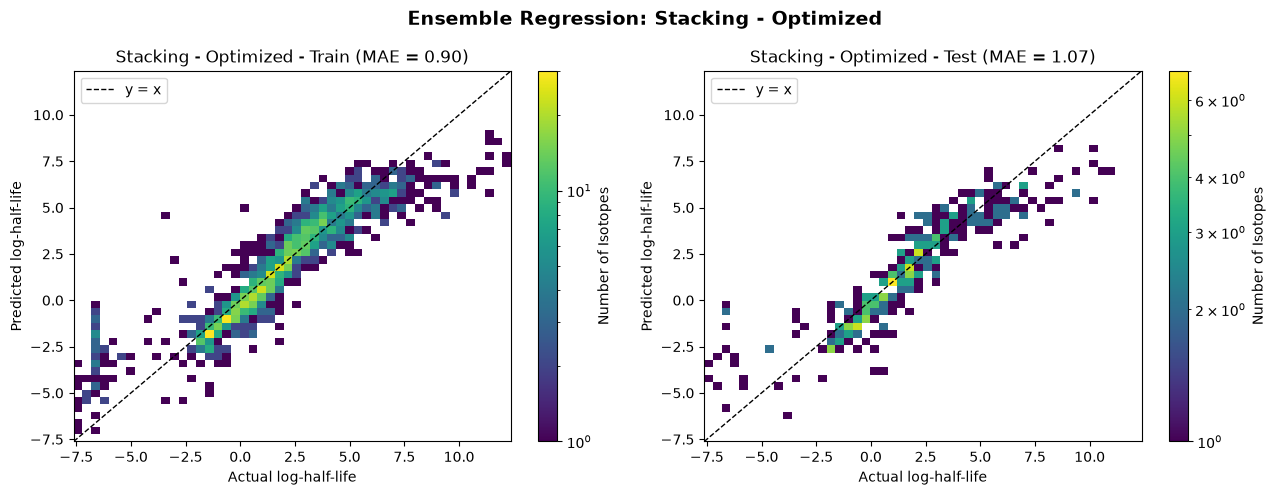


Regression Model Ranking by Test MAE



Rank  \
Model Category            Model                                               
Ensemble Regression       XGBoost - Optimized                             1   
Kernel Regression         Kernel Ridge (RBF) - Optimized                  2   
Ensemble Regression       Random Forest - Optimized                       3   
                          Random Forest - Baseline                        4   
Kernel Regression         Support Vector Regression (RBF) - Optimized     5   
Ensemble Regression       XGBoost - Baseline                              6   
Instance-Based Regression k-NN - Optimized                                7   
                          k-NN - Baseline                                 8   
Ensemble Regression       Stacking - Optimized                            9   
                          Stacking - Baseline                            10   
Tree-Based Regression     Decision Tree - Optimized                      11   
Kernel Regression         Kernel Ridge (RBF) - Baseline                  12   
Tree-Based Regression     Decision Tree - Baseline                       13   
Kernel Regression         Support Vector Regression (RBF) - Baseline     14   
Linear Regression         Polynomial - Optimized                         15   
                          Polynomial - Baseline                          16   
                          OLS - Baseline                                 17   
                          Ridge - Baseline                               18   
                          Lasso - Optimized                              19   
                          Elastic Net - Optimized                        20   
                          Ridge - Optimized                              21   
                          Elastic Net - Baseline                         22   
Dummy Regression          Dummy (median)                                 23   
Linear Regression         Lasso - Baseline                               24   
Dummy Regression          Dummy (mean)                                   25   

                                                                          mae  \
Model Category            Model                                                 
Ensemble Regression       XGBoost - Optimized                          0.8958   
Kernel Regression         Kernel Ridge (RBF) - Optimized               0.9210   
Ensemble Regression       Random Forest - Optimized                    0.9767   
                          Random Forest - Baseline                     0.9773   
Kernel Regression         Support Vector Regression (RBF) - Optimized  0.9952   
Ensemble Regression       XGBoost - Baseline                           0.9956   
Instance-Based Regression k-NN - Optimized                             1.0285   
                          k-NN - Baseline                              1.0669   
Ensemble Regression       Stacking - Optimized                         1.0695   
                          Stacking - Baseline                          1.0974   
Tree-Based Regression     Decision Tree - Optimized                    1.2046   
Kernel Regression         Kernel Ridge (RBF) - Baseline                1.2397   
Tree-Based Regression     Decision Tree - Baseline                     1.2573   
Kernel Regression         Support Vector Regression (RBF) - Baseline   1.3323   
Linear Regression         Polynomial - Optimized                       1.8599   
                          Polynomial - Baseline                        1.8599   
                          OLS - Baseline                               2.3705   
                          Ridge - Baseline                             2.3711   
                          Lasso - Optimized                            2.3760   
                          Elastic Net - Optimized                      2.3766   
                          Ridge - Optimized                            2.3772   
                          Elastic Net - Baseline                       2.5

In [9]:
# 8. Model Comparison and Visualization

# Combine all regression model results
df_all_results = pd.concat(
    {
        'Dummy Regression': df_dummy_comparison,
        'Linear Regression': df_linear_comparison,
        'Kernel Regression': df_kernel_comparison,
        'Tree-Based Regression': df_tree_comparison,
        'Instance-Based Regression': df_instance_comparison,
        'Ensemble Regression': df_ensemble_comparison
    },
    axis=0,
    names=['Model Category', 'Model']
)

# Convert index levels into regular columns
df_summary = df_all_results.reset_index()

# Create two-level column headers
df_summary.columns = pd.MultiIndex.from_tuples(
    [('', 'Model Category'), ('', 'Model')] +
    list(df_all_results.columns)
)

# Identify numerical metric columns
metric_cols = df_summary.columns[2:]

# Identify the first and last rows of each model category
categories = df_summary[('', 'Model Category')]

group_starts = categories.ne(categories.shift())
group_ends = categories.ne(categories.shift(-1))

# Add distinct borders around each model category
def style_model_groups(data):

    styles = pd.DataFrame(
        '', index=data.index, columns=data.columns
    )

    # Apply borders to each category section
    for i in range(len(data)):
        for j in range(len(data.columns)):

            borders = []

            if group_starts.iloc[i]:
                borders.append('border-top: 2px solid #666')

            if group_ends.iloc[i]:
                borders.append('border-bottom: 2px solid #666')

            if j == 0:
                borders.append('border-left: 2px solid #666')

            if j == len(data.columns) - 1:
                borders.append('border-right: 2px solid #666')

            styles.iloc[i, j] = '; '.join(borders)

    return styles


# Display formatted summary table
print("Comparison of All Regression Model Performance\n")

with pd.option_context(
    'display.max_rows', None,
    'display.max_columns', None,
    'display.max_colwidth', None,
    'display.width', 2000
):

    display(
        df_summary.style
        .format("{:.4f}", subset=metric_cols)
        .apply(style_model_groups, axis=None)
        .set_properties(**{
            'text-align': 'center',
            'vertical-align': 'middle'
        })
        .set_properties(
            subset=[('', 'Model')],
            **{'text-align': 'left'}
        )
        .set_table_styles([
            {
                'selector': 'th.col_heading',
                'props': [
                    ('text-align', 'center'),
                    ('vertical-align', 'middle'),
                    ('font-weight', 'bold')
                ]
            },
            {
                'selector': 'th.col_heading.level0',
                'props': [
                    ('text-align', 'center')
                ]
            },
            {
                'selector': 'th.col_heading.level1',
                'props': [
                    ('text-align', 'center')
                ]
            }
        ])
    )

# Combine fitted regression models
all_regressors = {
    'Dummy Regression': dummy_regressors,
    'Linear Regression': linear_comparison_regressors,
    'Kernel Regression': kernel_comparison_regressors,
    'Tree-Based Regression': tree_comparison_regressors,
    'Instance-Based Regression': instance_comparison_regressors,
    'Ensemble Regression': ensemble_comparison_regressors
}

# Select categories to visualize
# Set to None to generate plots for all categories
categories_to_plot = None

# Example:
# categories_to_plot = ['Linear Regression', 'Kernel Regression']

# Generate plots for each model category
for category, regressors in all_regressors.items():

    # Skip categories that are not selected
    if (
        categories_to_plot is not None
        and category not in categories_to_plot
    ):
        continue

    print(f"\n{category} Parity Plots\n")

    for name, model in regressors.items():

        # Predict training and testing values
        y_train_pred = model.predict(df_train[FEATURES])
        y_test_pred = model.predict(df_test[FEATURES])

        # Determine shared axis limits
        lims = [
            min(
                df_train[TARGET].min(),
                df_test[TARGET].min(),
                y_train_pred.min(),
                y_test_pred.min()
            ),
            max(
                df_train[TARGET].max(),
                df_test[TARGET].max(),
                y_train_pred.max(),
                y_test_pred.max()
            )
        ]

        # Create side-by-side subplots
        fig, axes = plt.subplots(
            1, 2, figsize=(13, 5)
        )

        # Training parity plot
        hist_density(
            df_train[TARGET],
            y_train_pred,
            xlabel='Actual log-half-life',
            ylabel='Predicted log-half-life',
            title=f'{name} - Train',
            ax=axes[0],
            lims=lims
        )

        # Testing parity plot
        hist_density(
            df_test[TARGET],
            y_test_pred,
            xlabel='Actual log-half-life',
            ylabel='Predicted log-half-life',
            title=f'{name} - Test',
            ax=axes[1],
            lims=lims
        )

        # Add overall figure title
        fig.suptitle(
            f'{category}: {name}',
            fontsize=14,
            fontweight='bold'
        )

        plt.tight_layout()
        plt.show()

# Rank all models by testing MAE

# Extract test results
df_test_ranking = df_all_results['Test'].copy()

# Sort models by testing MAE (lower is better)
df_test_ranking = df_test_ranking.sort_values(
    by='mae',
    ascending=True
)

# Add numerical ranking
df_test_ranking.insert(
    0,
    'Rank',
    range(1, len(df_test_ranking) + 1)
)

print("\nRegression Model Ranking by Test MAE\n")

display(df_test_ranking.round(4))

